# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Jeika Antama Syalom Tarigan
- **Email:** ds284b6y0831@student.devacademy.id
- **ID Dicoding:** ds284b6y0831

## Deskripsi Proyek
Proyek ini bertujuan untuk menganalisis pola penyewaan sepeda berdasarkan waktu, kondisi cuaca, dan karakteristik pengguna menggunakan Bike Sharing Dataset. Data berisi catatan penyewaan sepeda Capital Bikeshare di Washington, D.C., selama Januari 2011 hingga Desember 2012. Analisis dilakukan melalui tahapan Data Wrangling, Exploratory Data Analysis (EDA), visualisasi, serta analisis lanjutan menggunakan teknik binning.

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa rata-rata jumlah penyewaan sepeda mencapai nilai tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama periode Januari 2011 hingga Desember 2012?
- **Pertanyaan 3:** Bagaimana perbandingan rata-rata penyewaan sepeda oleh pengguna kasual dan terdaftar antara hari kerja dan hari bukan kerja selama periode Januari 2011 hingga Desember 2012?
- **Pertanyaan 4:** Bagaimana distribusi tingkat permintaan penyewaan sepeda ke dalam kategori rendah, sedang, dan tinggi berdasarkan jumlah penyewaan harian selama periode Januari 2011 hingga Desember 2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
sns.set_theme(style='whitegrid')

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


## Data Wrangling

### Gathering Data

#### Memuat dataset harian dan per jam

Dataset Bike Sharing terdiri dari dua file, yaitu `day.csv` untuk data penyewaan harian dan `hour.csv` untuk data penyewaan per jam. Unggah file ZIP dataset melalui Google Colab, kemudian ekstrak dan baca kedua file CSV berikut.

In [2]:
from google.colab import files
uploaded = files.upload()
zip_filename = next(
    (name for name in uploaded.keys() if name.lower().endswith('.zip')),
    None)
if zip_filename is None:
    raise FileNotFoundError("Silakan unggah file ZIP Bike Sharing Dataset.")
os.makedirs('data', exist_ok=True)
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('data')
print("Isi folder data:", os.listdir('data'))
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')
print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)
display(day_df.head())
display(hour_df.head())

Saving Bike-sharing-dataset.zip to Bike-sharing-dataset.zip
Isi folder data: ['hour.csv', 'day.csv', 'Readme.txt']
Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi data penyewaan yang telah diagregasi per hari, sedangkan `hour.csv` berisi data penyewaan per jam.
- Kedua dataset digunakan agar pola penyewaan dapat dianalisis dari sisi harian maupun per jam.

### Assessing Data

#### Memeriksa kualitas dan karakteristik data

Pemeriksaan dilakukan terhadap struktur data, missing value, data duplikat, statistik deskriptif, nilai unik pada kolom kategorikal, konsistensi total penyewaan, serta rentang variabel numerik.

In [4]:
# Informasi struktur dan tipe data
print("Informasi Dataset Harian")
day_df.info()
print("\nInformasi Dataset Per Jam")
hour_df.info()
# Missing value
print("\nMissing Value Dataset Harian:")
display(day_df.isnull().sum())
print("\nMissing Value Dataset Per Jam:")
display(hour_df.isnull().sum())
# Data duplikat
print("\nJumlah Duplikat Dataset Harian:", day_df.duplicated().sum())
print("Jumlah Duplikat Dataset Per Jam:", hour_df.duplicated().sum())
# Statistik deskriptif
print("\nStatistik Dataset Harian")
display(day_df.describe())
print("Statistik Dataset Per Jam")
display(hour_df.describe())
# Nilai unik variabel kategorikal
categorical_columns = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit']
for column in categorical_columns:
    print(f"\nNilai unik {column}:")
    print(sorted(day_df[column].unique()))
# Konsistensi jumlah penyewaan
print("\nKetidaksesuaian Dataset Harian:",
      (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum())
print("Ketidaksesuaian Dataset Per Jam:",
      (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum())
# Rentang variabel numerik yang telah dinormalisasi
normalized_columns = ['temp', 'atemp', 'hum', 'windspeed']
print("\nRentang Nilai Dataset Harian")
display(day_df[normalized_columns].agg(['min', 'max']))
print("Rentang Nilai Dataset Per Jam")
display(hour_df[normalized_columns].agg(['min', 'max']))

Informasi Dataset Harian
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Informasi Dataset Per Jam
<class 'pandas.core.frame.DataFrame'>
Ran

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0



Missing Value Dataset Per Jam:


,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0



Jumlah Duplikat Dataset Harian: 0
Jumlah Duplikat Dataset Per Jam: 0

Statistik Dataset Harian


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


... (2 outputs left out)


Nilai unik season:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Nilai unik yr:
[np.int64(0), np.int64(1)]

Nilai unik mnth:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Nilai unik holiday:
[np.int64(0), np.int64(1)]

Nilai unik weekday:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Nilai unik workingday:
[np.int64(0), np.int64(1)]

Nilai unik weathersit:
[np.int64(1), np.int64(2), np.int64(3)]

Ketidaksesuaian Dataset Harian: 0
Ketidaksesuaian Dataset Per Jam: 0

Rentang Nilai Dataset Harian


,temp,atemp,hum,windspeed
min,0.059130,0.079070,0.0000,0.022392
max,0.861667,0.840896,0.9725,0.507463


Rentang Nilai Dataset Per Jam


,temp,atemp,hum,windspeed
min,0.02,0.0,0.0,0.0000
max,1.00,1.0,1.0,0.8507


**Steps to Take:**
- Memastikan apakah terdapat missing value dan data duplikat pada kedua dataset.
- Memeriksa tipe data dan nilai unik pada variabel kategorikal.
- Memeriksa kesesuaian jumlah pengguna kasual dan terdaftar terhadap total penyewaan.
- Memeriksa rentang nilai variabel numerik untuk mengetahui karakteristik datanya.

**Insight:**
- Berdasarkan pemeriksaan dataset, tidak ditemukan missing value maupun data duplikat.
- Jumlah penyewaan konsisten karena penjumlahan pengguna kasual dan terdaftar sesuai dengan total penyewaan.
- Nilai variabel kategorikal berada pada rentang kategori yang diharapkan. Pemeriksaan lebih lanjut dilakukan saat tahap cleaning.

### Cleaning Data

#### Memperbaiki tipe data dan memvalidasi nilai

Pembersihan dilakukan dengan membuat salinan dataset, mengubah kolom tanggal menjadi tipe datetime, dan memvalidasi nilai pada variabel kategorikal serta jam. Data tidak dihapus karena pemeriksaan awal tidak menemukan missing value maupun data duplikat.

In [5]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()
# Mengubah tipe data tanggal
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])
print("Tipe data tanggal harian:", day_clean['dteday'].dtype)
print("Tipe data tanggal per jam:", hour_clean['dteday'].dtype)
# Memvalidasi nilai kategorikal
valid_values = {
    'season': [1, 2, 3, 4],
    'yr': [0, 1],
    'mnth': list(range(1, 13)),
    'holiday': [0, 1],
    'weekday': list(range(7)),
    'workingday': [0, 1],
    'weathersit': [1, 2, 3, 4]}
for column, allowed in valid_values.items():
    invalid_day = ~day_clean[column].isin(allowed)
    invalid_hour = ~hour_clean[column].isin(allowed)
    print(f"\nKolom {column}")
    print("Nilai tidak valid pada day.csv:", invalid_day.sum())
    print("Nilai tidak valid pada hour.csv:", invalid_hour.sum())
# Memvalidasi rentang jam pada dataset per jam
invalid_hour_value = ~hour_clean['hr'].between(0, 23)
print("\nNilai jam tidak valid:", invalid_hour_value.sum())
# Pemeriksaan akhir setelah cleaning
print("\nPemeriksaan Dataset Harian")
print("Missing value:", day_clean.isnull().sum().sum())
print("Duplicate:", day_clean.duplicated().sum())
print("\nPemeriksaan Dataset Per Jam")
print("Missing value:", hour_clean.isnull().sum().sum())
print("Duplicate:", hour_clean.duplicated().sum())
# Menyimpan dataset bersih
day_clean.to_csv('data/day_clean.csv', index=False)
hour_clean.to_csv('data/hour_clean.csv', index=False)

print("\nDataset bersih berhasil disimpan.")

Tipe data tanggal harian: datetime64[ns]
Tipe data tanggal per jam: datetime64[ns]

Kolom season
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom yr
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom mnth
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom holiday
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom weekday
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom workingday
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Kolom weathersit
Nilai tidak valid pada day.csv: 0
Nilai tidak valid pada hour.csv: 0

Nilai jam tidak valid: 0

Pemeriksaan Dataset Harian
Missing value: 0
Duplicate: 0

Pemeriksaan Dataset Per Jam
Missing value: 0
Duplicate: 0

Dataset bersih berhasil disimpan.


In [13]:
# Menyimpan dataset hasil cleaning
day_clean.to_csv('day_data.csv', index=False)
hour_clean.to_csv('hour_data.csv', index=False)
print("Dataset bersih berhasil disimpan!")

Dataset bersih berhasil disimpan!


**Insight:**
- Kolom `dteday` pada kedua dataset telah diubah menjadi tipe datetime sehingga dapat digunakan untuk analisis berbasis waktu.
- Tidak ditemukan nilai kategorikal maupun nilai jam yang tidak valid.
- Dataset hasil pembersihan disimpan sebagai `day_clean.csv` dan `hour_clean.csv`.

## Exploratory Data Analysis (EDA)

### Eksplorasi pola penyewaan berdasarkan waktu, cuaca, dan tipe pengguna

Tahap EDA dilakukan untuk menjawab empat pertanyaan bisnis. Analisis menggunakan rata-rata penyewaan per jam, rata-rata penyewaan harian berdasarkan cuaca, perbandingan tipe pengguna berdasarkan jenis hari, serta pengelompokan tingkat permintaan harian.

In [6]:
# 1. Rata-rata penyewaan berdasarkan jam
hourly_rentals = (
    hour_clean.groupby('hr')['cnt']
    .mean()
    .reset_index())
highest_hour = hourly_rentals.loc[hourly_rentals['cnt'].idxmax()]
lowest_hour = hourly_rentals.loc[hourly_rentals['cnt'].idxmin()]
display(hourly_rentals)
print(
    f"Jam dengan penyewaan tertinggi: {int(highest_hour['hr']):02d}.00 "
    f"dengan rata-rata {highest_hour['cnt']:.2f} penyewaan.")
print(
    f"Jam dengan penyewaan terendah: {int(lowest_hour['hr']):02d}.00 "
    f"dengan rata-rata {lowest_hour['cnt']:.2f} penyewaan.")
# 2. Rata-rata penyewaan berdasarkan kondisi cuaca
weather_rentals = (
    day_clean.groupby('weathersit')['cnt']
    .mean()
    .reset_index())
weather_labels = {
    1: 'Cerah',
    2: 'Berkabut/Berawan',
    3: 'Hujan Ringan/Salju Ringan',
    4: 'Cuaca Buruk'}
weather_rentals['weather'] = weather_rentals['weathersit'].map(weather_labels)
display(weather_rentals)
# 3. Perbandingan pengguna kasual dan terdaftar berdasarkan jenis hari
user_analysis = (
    hour_clean.groupby('workingday')[['casual', 'registered']]
    .mean()
    .reset_index())
user_analysis['day_type'] = user_analysis['workingday'].map({
    0: 'Hari Bukan Kerja',
    1: 'Hari Kerja'})
display(user_analysis)
# 4. Distribusi tingkat permintaan harian menggunakan qcut
day_clean['demand_category'] = pd.qcut(
    day_clean['cnt'],
    q=3,
    labels=['Rendah', 'Sedang', 'Tinggi'])
demand_distribution = (
    day_clean['demand_category']
    .value_counts()
    .sort_index()
    .reset_index())
demand_distribution.columns = ['Kategori Permintaan', 'Jumlah Hari']
demand_distribution['Persentase (%)'] = (
    demand_distribution['Jumlah Hari'] / len(day_clean) * 100).round(2)
display(demand_distribution)

,hr,cnt
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


Jam dengan penyewaan tertinggi: 17.00 dengan rata-rata 461.45 penyewaan.
Jam dengan penyewaan terendah: 04.00 dengan rata-rata 6.35 penyewaan.


,weathersit,cnt,weather
0,1,4876.786177,Cerah
1,2,4035.862348,Berkabut/Berawan
2,3,1803.285714,Hujan Ringan/Salju Ringan


,workingday,casual,registered,day_type
0,0,57.441422,123.963910,Hari Bukan Kerja
1,1,25.561315,167.646439,Hari Kerja


,Kategori Permintaan,Jumlah Hari,Persentase (%)
0,Rendah,244,33.38
1,Sedang,244,33.38
2,Tinggi,243,33.24


**Insight:**
- Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, sedangkan terendah terjadi pada pukul 04.00.
- Rata-rata penyewaan harian tertinggi terdapat pada kondisi cuaca cerah dan terendah pada hujan ringan atau salju ringan.
- Pengguna terdaftar memiliki rata-rata penyewaan lebih tinggi pada hari kerja, sedangkan pengguna kasual lebih tinggi pada hari bukan kerja.
- Penggunaan `qcut` membagi data harian menjadi tiga kelompok kuantil dengan jumlah hari yang hampir sama.

## Visualization & Explanatory Analysis

### Pertanyaan 1
Pada jam berapa rata-rata jumlah penyewaan sepeda mencapai nilai tertinggi dan terendah selama periode Januari 2011 hingga Desember 2012?

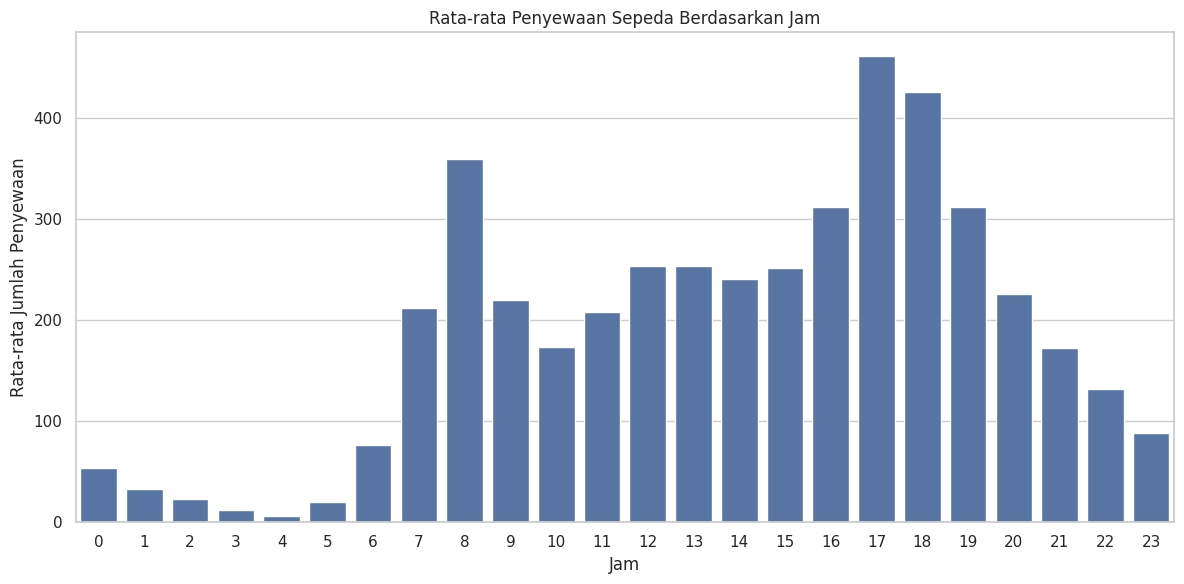

Puncak penyewaan: pukul 17.00 (461.45 penyewaan).
Penyewaan terendah: pukul 04.00 (6.35 penyewaan).


In [7]:
plt.figure(figsize=(12, 6))
sns.barplot(data=hourly_rentals, x='hr', y='cnt')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Jam')
plt.xlabel('Jam')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(24))
plt.tight_layout()
plt.show()

print(
    f"Puncak penyewaan: pukul {int(highest_hour['hr']):02d}.00 "
    f"({highest_hour['cnt']:.2f} penyewaan)."
)
print(
    f"Penyewaan terendah: pukul {int(lowest_hour['hr']):02d}.00 "
    f"({lowest_hour['cnt']:.2f} penyewaan)."
)

### Pertanyaan 2
Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama periode Januari 2011 hingga Desember 2012?

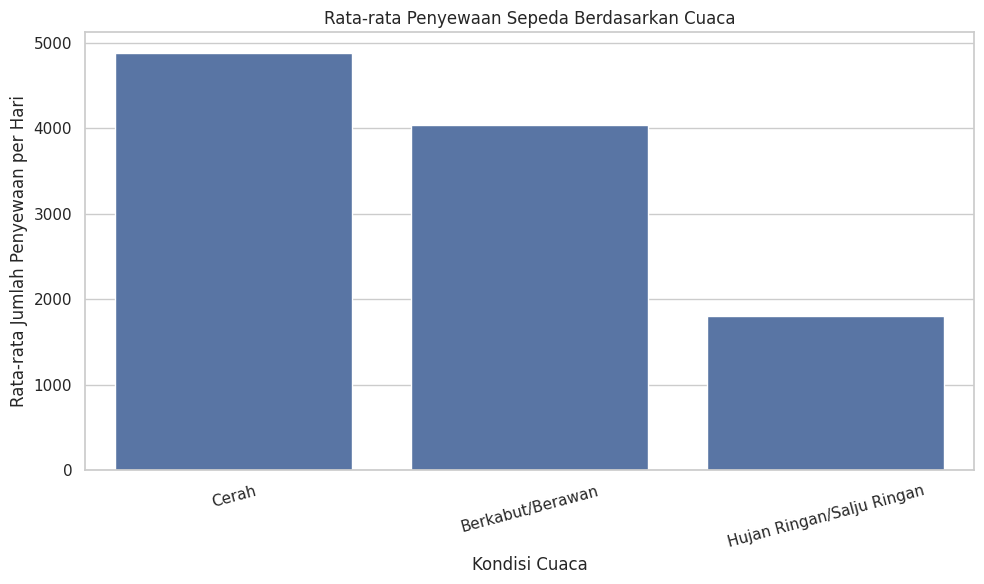

,weather,cnt
0,Cerah,4876.786177
1,Berkabut/Berawan,4035.862348
2,Hujan Ringan/Salju Ringan,1803.285714


In [8]:
plt.figure(figsize=(10, 6))
sns.barplot(data=weather_rentals, x='weather', y='cnt')

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Cuaca')
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Jumlah Penyewaan per Hari')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

display(weather_rentals[['weather', 'cnt']])

**Insight:**
- Visualisasi pertama menunjukkan puncak rata-rata penyewaan pada pukul 17.00 dan titik terendah pada pukul 04.00.
- Visualisasi kedua menunjukkan rata-rata penyewaan paling tinggi saat cuaca cerah (4.876,79) dan paling rendah saat hujan ringan atau salju ringan (1.803,29).
- Kondisi cuaca yang lebih baik cenderung diikuti jumlah penyewaan yang lebih tinggi.

### Pertanyaan 3
Bagaimana perbandingan rata-rata penyewaan sepeda oleh pengguna kasual dan terdaftar antara hari kerja dan hari bukan kerja selama periode Januari 2011 hingga Desember 2012?

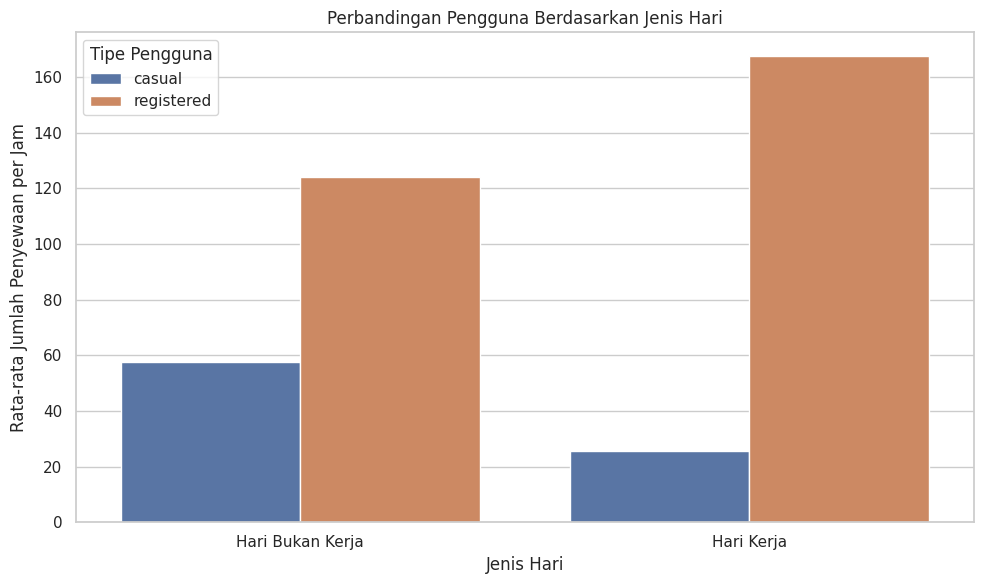

,workingday,casual,registered,day_type
0,0,57.441422,123.963910,Hari Bukan Kerja
1,1,25.561315,167.646439,Hari Kerja


In [9]:
user_analysis_melted = user_analysis.melt(
    id_vars='day_type',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='average_rentals'
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=user_analysis_melted,
    x='day_type',
    y='average_rentals',
    hue='user_type'
)

plt.title('Perbandingan Pengguna Berdasarkan Jenis Hari')
plt.xlabel('Jenis Hari')
plt.ylabel('Rata-rata Jumlah Penyewaan per Jam')
plt.legend(title='Tipe Pengguna')
plt.tight_layout()
plt.show()

display(user_analysis)

### Pertanyaan 4
Bagaimana distribusi tingkat permintaan penyewaan sepeda ke dalam kategori rendah, sedang, dan tinggi berdasarkan jumlah penyewaan harian selama periode Januari 2011 hingga Desember 2012?

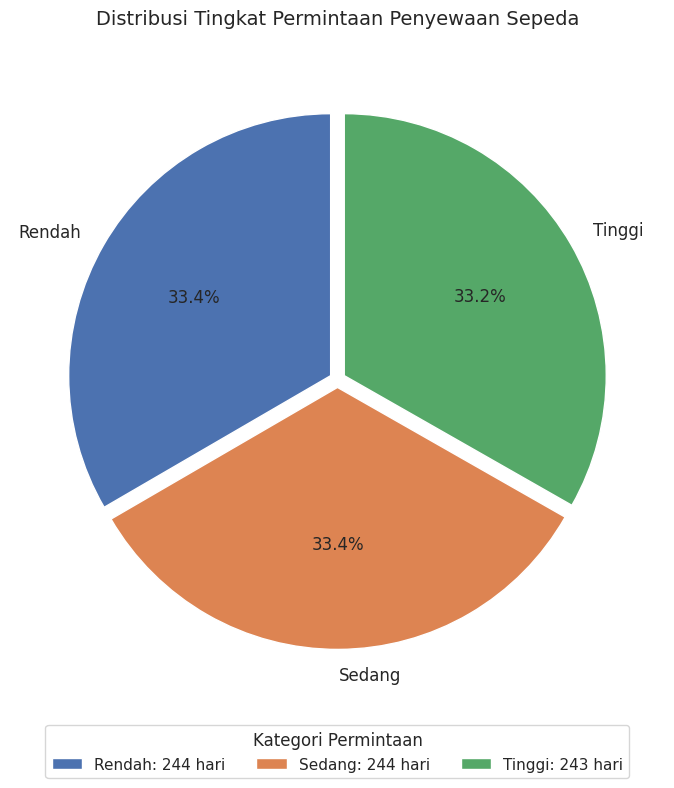

,Kategori Permintaan,Jumlah Hari,Persentase (%)
0,Rendah,244,33.38
1,Sedang,244,33.38
2,Tinggi,243,33.24


In [10]:
demand_counts = (
    day_clean['demand_category']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 8))
plt.pie(
    demand_counts,
    labels=demand_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.03, 0.03, 0.03),
    shadow=False,
    textprops={'fontsize': 12}
)

plt.title('Distribusi Tingkat Permintaan Penyewaan Sepeda', fontsize=14, pad=20)
plt.legend(
    labels=[
        f'{category}: {count} hari'
        for category, count in demand_counts.items()
    ],
    title='Kategori Permintaan',
    loc='lower center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)
plt.tight_layout()
plt.show()

display(demand_distribution)

**Insight tambahan:**
- Pengguna terdaftar rata-rata lebih banyak menyewa sepeda pada hari kerja, sedangkan pengguna kasual lebih banyak pada hari bukan kerja.
- Distribusi kategori permintaan rendah, sedang, dan tinggi terlihat hampir seimbang karena kategori dibentuk menggunakan pembagian kuantil (`qcut`). Hasil ini menunjukkan pembagian jumlah hari, bukan berarti total penyewaan pada setiap kategori sama.

## Analisis Lanjutan (Opsional)

In [12]:
demand_summary = (
    day_clean.groupby('demand_category', observed=False)['cnt']
    .agg(['count', 'min', 'max', 'mean'])
    .reset_index())
demand_summary.columns = [
    'Kategori Permintaan', 'Jumlah Hari',
    'Minimum Penyewaan', 'Maksimum Penyewaan', 'Rata-rata Penyewaan']
display(demand_summary)

,Kategori Permintaan,Jumlah Hari,Minimum Penyewaan,Maksimum Penyewaan,Rata-rata Penyewaan
0,Rendah,244,22,3740,2312.065574
1,Sedang,244,3744,5312,4522.225410
2,Tinggi,243,5315,8714,6687.703704


**Insight:**
- Binning dengan `qcut` membagi data jumlah penyewaan harian menjadi tiga kelompok berdasarkan kuantil.
- Jumlah hari pada kategori rendah, sedang, dan tinggi hampir sama. Nilai minimum, maksimum, dan rata-rata tiap kategori membantu melihat rentang permintaan yang diwakili masing-masing kelompok.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu sekitar 461,45 penyewaan, sedangkan rata-rata terendah terjadi pada pukul 04.00, yaitu sekitar 6,35 penyewaan.
- **Conclusion pertanyaan 2:** Rata-rata penyewaan harian tertinggi terjadi saat cuaca cerah (4.876,79), kemudian berkabut/berawan (4.035,86), dan terendah saat hujan ringan atau salju ringan (1.803,29).
- **Conclusion pertanyaan 3:** Pengguna terdaftar lebih aktif pada hari kerja (rata-rata 167,65 penyewaan per jam), sedangkan pengguna kasual lebih aktif pada hari bukan kerja (rata-rata 57,44 penyewaan per jam).
- **Conclusion pertanyaan 4:** Kategori permintaan rendah, sedang, dan tinggi masing-masing mencakup 244, 244, dan 243 hari. Proporsi yang hampir sama merupakan konsekuensi dari metode kuantil (`qcut`) yang digunakan untuk membagi data.

Secara keseluruhan, hasil analisis menunjukkan bahwa pola penyewaan sepeda berbeda berdasarkan waktu, cuaca, dan tipe pengguna. Informasi ini dapat digunakan sebagai dasar untuk mengatur ketersediaan sepeda dan strategi layanan.

**Rekomendasi Action Item:**
- Menambah atau mengatur ketersediaan sepeda dan petugas operasional pada jam-jam dengan permintaan tinggi, terutama sekitar pukul 07.00–09.00 dan 16.00–18.00.
- Menyesuaikan perawatan, kesiapan armada, dan informasi layanan dengan kondisi cuaca, karena penyewaan cenderung menurun saat cuaca kurang mendukung.
- Menyusun program berlangganan atau loyalitas untuk pengguna terdaftar, serta promosi rekreasi atau akhir pekan untuk menarik pengguna kasual.
- Menggunakan kategori permintaan sebagai salah satu dasar pemantauan kebutuhan operasional. Kategori hasil `qcut` perlu ditafsirkan sebagai kelompok relatif dalam dataset, bukan batas permintaan absolut.